In [1]:
# %% 1. Import & baca data
import pandas as pd

data = pd.read_csv(r"C:\Users\s2\Documents\RKI\BRFSS\brfss2024.csv")
print(f"Ukuran awal: {data.shape}")

# %% 2. Filter dulu: hanya DIABETE4 == 1
print(data['DIABETE4'].value_counts(dropna=False))

data = data[data['DIABETE4'] == 1].copy()
data = data.reset_index(drop=True)

print(f"Ukuran setelah filter: {data.shape}")
print(data['DIABETE4'].value_counts())

Ukuran awal: (457670, 301)
DIABETE4
3.0    376125
1.0     65809
4.0     11307
2.0      3395
7.0       798
9.0       232
NaN         4
Name: count, dtype: int64
Ukuran setelah filter: (65809, 301)
DIABETE4
1.0    65809
Name: count, dtype: int64


In [2]:
data

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,...,_LCSCTSN,_LCSPSTF,DRNKANY6,DROCDY4_,_RFBING6,_DRNKWK3,_RFDRHV9,_FLSHOT7,_PNEUMO3,_AIDTST4
0,1.0,2.0,2212024,2.0,21.0,2024,1100.0,2024000006,2.024000e+09,1.0,...,3.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,NaN,NaN,2.0
1,1.0,2.0,2212024,2.0,21.0,2024,1100.0,2024000008,2.024000e+09,1.0,...,2.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,2.0,1.0,2.0
2,1.0,2.0,2262024,2.0,26.0,2024,1100.0,2024000010,2.024000e+09,1.0,...,1.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0,2.0,2.0
3,1.0,2.0,3052024,3.0,5.0,2024,1100.0,2024000015,2.024000e+09,1.0,...,4.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0,1.0,2.0
4,1.0,3.0,3202024,3.0,20.0,2024,1100.0,2024000020,2.024000e+09,1.0,...,3.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,NaN,NaN,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65804,78.0,7.0,7122024,7.0,12.0,2024,1100.0,2024001311,2.024001e+09,NaN,...,3.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,NaN,NaN,2.0
65805,78.0,7.0,7222024,7.0,22.0,2024,1100.0,2024001321,2.024001e+09,NaN,...,4.0,9.0,1.0,3.000000e+00,1.0,4.700000e+01,1.0,NaN,NaN,2.0
65806,78.0,7.0,7192024,7.0,19.0,2024,1100.0,2024001325,2.024001e+09,NaN,...,3.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,NaN,NaN,1.0
65807,78.0,7.0,7172024,7.0,17.0,2024,1100.0,2024001341,2.024001e+09,NaN,...,NaN,NaN,1.0,7.000000e+00,2.0,1.870000e+02,1.0,NaN,NaN,2.0


In [3]:
# %% 3. Cek missing value (dihitung dari data diabetes saja)
missing = data.isnull().sum()
missing_pct = (missing / len(data)) * 100

missing_df = pd.DataFrame({
    'jumlah_kosong': missing,
    'persen_kosong': missing_pct.round(2)
})
missing_df = (missing_df[missing_df['jumlah_kosong'] > 0]
              .sort_values('persen_kosong', ascending=False))

print(f"Total fitur           : {data.shape[1]}")
print(f"Fitur yang ada kosong : {len(missing_df)}")
print(missing_df.head(20))

Total fitur           : 301
Fitur yang ada kosong : 230
          jumlah_kosong  persen_kosong
COLGHOUS          65807         100.00
PDIABTS1          65809         100.00
PREDIAB2          65809         100.00
RCSXBRTH          65809         100.00
RCSGEND1          65809         100.00
CCLGHOUS          65759          99.92
ICFQSTVR          65736          99.89
HPVDSHT           65739          99.89
CSRVCTL2          65675          99.80
HPVADSH1          65666          99.78
NOBCUSE8          65625          99.72
TYPCNTR9          65378          99.35
CSRVINST          65302          99.23
CASTHNO2          65281          99.20
PFPPRVN4          65186          99.05
USEMRJN4          65128          98.97
CSRVCLIN          65102          98.93
CSRVDEIN          65102          98.93
CSRVINSR          65100          98.92
CSRVRTRN          65097          98.92


In [4]:
# %% 4. Hapus fitur dengan missing value > 15%
cols_to_drop = missing_pct[missing_pct >= 20].index

print(f"Jumlah fitur yang dihapus: {len(cols_to_drop)}")
print(missing_pct[cols_to_drop].sort_values(ascending=False).head(20))

data = data.drop(columns=cols_to_drop)
print(f"Sisa fitur: {data.shape[1]}")


Jumlah fitur yang dihapus: 181
PDIABTS1    100.000000
RCSXBRTH    100.000000
RCSGEND1    100.000000
PREDIAB2    100.000000
COLGHOUS     99.996961
CCLGHOUS     99.924023
HPVDSHT      99.893632
ICFQSTVR     99.889073
CSRVCTL2     99.796380
HPVADSH1     99.782704
NOBCUSE8     99.720403
TYPCNTR9     99.345074
CSRVINST     99.229589
CASTHNO2     99.197678
PFPPRVN4     99.053321
USEMRJN4     98.965187
CSRVDEIN     98.925679
CSRVCLIN     98.925679
CSRVINSR     98.922640
CSRVRTRN     98.918081
dtype: float64
Sisa fitur: 120


In [5]:
sisa = data.isnull().sum()
sisa_pct = (sisa / len(data) * 100).round(2)

sisa_df = pd.DataFrame({'jumlah': sisa, 'persen': sisa_pct})
sisa_df = sisa_df[sisa_df['jumlah'] > 0].sort_values('persen', ascending=False)

print(f"Fitur yang masih punya kosong: {len(sisa_df)} dari {data.shape[1]}")
print(sisa_df)

Fitur yang masih punya kosong: 49 dari 120
          jumlah  persen
_LCSCTSN   10290   15.64
_HADCOLN    9400   14.28
_HADSIGM    9400   14.28
COLNCNCR    8379   12.73
HADSIGM4    8027   12.20
_LCSELIG    7641   11.61
_LCSPSTF    7641   11.61
_LCSSMKG    7641   11.61
HIVRISK5    6198    9.42
_AIDTST4    5918    8.99
HIVTST7     5918    8.99
PNEUVAC4    5832    8.86
_BMI5       5652    8.59
FLUSHOT7    5651    8.59
_BMI5CAT    5652    8.59
ALCDAY4     5379    8.17
LCSCTSC1    5019    7.63
WTKG3       4966    7.55
ECIGNOW3    4164    6.33
USENOW3     4038    6.14
SMOKE100    3926    5.97
HTIN4       3587    5.45
HTM4        3033    4.61
DIFFALON    2626    3.99
DIFFDRES    2500    3.80
DIFFWALK    2396    3.64
_METSTAT    2327    3.54
_URBSTAT    2327    3.54
DECIDE      2226    3.38
BLIND       2069    3.14
DEAF        1935    2.94
HEIGHT3     1682    2.56
WEIGHT2     1554    2.36
_MICHD      1223    1.86
INCOME3     1095    1.66
CHILDREN     599    0.91
EMPLOY1      389    0.59
_DRDXAR

In [6]:
data.isna().sum()

_STATE         0
FMONTH         0
IDATE          0
IMONTH         0
IDAY           0
            ... 
DROCDY4_       0
_RFBING6       0
_DRNKWK3       0
_RFDRHV9       0
_AIDTST4    5918
Length: 120, dtype: int64

In [7]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 65809 entries, 0 to 65808
Columns: 120 entries, _STATE to _AIDTST4
dtypes: float64(117), int64(3)
memory usage: 60.3 MB


In [8]:
import pandas as pd

pd.set_option("display.max_rows", 200)

# 1. value_counts semua kolom, NaN ikut dihitung
for col in data.columns:
    print(f"\n=== {col} | unik: {data[col].nunique()} | NaN: {data[col].isna().sum()} ===")
    print(data[col].value_counts(dropna=False).head(15))


=== _STATE | unik: 53 | NaN: 0 ===
_STATE
36.0    5859
53.0    3105
18.0    2221
24.0    2207
12.0    2130
55.0    2098
26.0    1848
45.0    1839
48.0    1811
27.0    1781
31.0    1760
39.0    1684
20.0    1683
23.0    1681
17.0    1664
Name: count, dtype: int64

=== FMONTH | unik: 12 | NaN: 0 ===
FMONTH
7.0     6728
8.0     5755
9.0     5679
4.0     5662
3.0     5505
5.0     5491
11.0    5413
10.0    5394
2.0     5391
6.0     5383
1.0     5035
12.0    4373
Name: count, dtype: int64

=== IDATE | unik: 423 | NaN: 0 ===
IDATE
12102024    323
6112024     306
12112024    302
7092024     300
7102024     297
7022024     296
12172024    293
7082024     292
8012024     291
5072024     290
6182024     289
6042024     289
6202024     289
6062024     288
6242024     288
Name: count, dtype: int64

=== IMONTH | unik: 12 | NaN: 0 ===
IMONTH
7.0     6504
6.0     6239
8.0     6076
5.0     6031
12.0    5631
10.0    5485
4.0     5413
11.0    5412
3.0     5261
9.0     5097
2.0     4996
1.0     3664
Name


=== HAVARTH4 | unik: 4 | NaN: 0 ===
HAVARTH4
1.0    35530
2.0    29918
7.0      349
9.0       12
Name: count, dtype: int64

=== DIABETE4 | unik: 1 | NaN: 0 ===
DIABETE4
1.0    65809
Name: count, dtype: int64

=== DIABAGE4 | unik: 98 | NaN: 0 ===
DIABAGE4
50.0    5936
60.0    4506
98.0    3897
40.0    3801
55.0    3794
45.0    3084
65.0    2632
70.0    1774
35.0    1686
30.0    1655
58.0    1363
62.0    1270
52.0    1269
48.0    1162
42.0    1086
Name: count, dtype: int64

=== MARITAL | unik: 7 | NaN: 0 ===
MARITAL
1.0    32405
3.0    11241
2.0    10666
5.0     7803
4.0     1641
6.0     1615
9.0      438
Name: count, dtype: int64

=== EDUCA | unik: 7 | NaN: 0 ===
EDUCA
6.0    21253
5.0    19523
4.0    19042
3.0     3362
2.0     2153
9.0      285
1.0      191
Name: count, dtype: int64

=== RENTHOM1 | unik: 5 | NaN: 0 ===
RENTHOM1
1.0    47162
2.0    15462
3.0     2726
9.0      315
7.0      144
Name: count, dtype: int64

=== CPDEMO1C | unik: 9 | NaN: 0 ===
CPDEMO1C
1.0    57435
2.0     4

In [9]:
data['_STATE'].value_counts()

_STATE
36.0    5859
53.0    3105
18.0    2221
24.0    2207
12.0    2130
55.0    2098
26.0    1848
45.0    1839
48.0    1811
27.0    1781
31.0    1760
39.0    1684
20.0    1683
23.0    1681
17.0    1664
21.0    1497
49.0    1407
4.0     1259
54.0    1249
13.0    1242
19.0    1228
51.0    1216
40.0    1131
6.0     1116
8.0     1062
29.0    1040
34.0    1037
5.0     1002
25.0    1001
33.0     985
1.0      968
9.0      950
46.0     896
15.0     851
30.0     827
38.0     826
72.0     815
41.0     806
22.0     802
10.0     744
44.0     736
50.0     681
56.0     652
2.0      598
37.0     580
35.0     524
42.0     502
16.0     492
28.0     462
11.0     353
32.0     348
66.0     322
78.0     231
Name: count, dtype: int64

In [10]:
import pandas as pd

pd.set_option("display.max_rows", 200)

# 1. value_counts semua kolom, NaN ikut dihitung
for col in data.columns:
    print(f"\n=== {col} | unik: {data[col].nunique()} | NaN: {data[col].isna().sum()} ===")
    print(data[col].value_counts(dropna=False).head(15))


=== _STATE | unik: 53 | NaN: 0 ===
_STATE
36.0    5859
53.0    3105
18.0    2221
24.0    2207
12.0    2130
55.0    2098
26.0    1848
45.0    1839
48.0    1811
27.0    1781
31.0    1760
39.0    1684
20.0    1683
23.0    1681
17.0    1664
Name: count, dtype: int64

=== FMONTH | unik: 12 | NaN: 0 ===
FMONTH
7.0     6728
8.0     5755
9.0     5679
4.0     5662
3.0     5505
5.0     5491
11.0    5413
10.0    5394
2.0     5391
6.0     5383
1.0     5035
12.0    4373
Name: count, dtype: int64

=== IDATE | unik: 423 | NaN: 0 ===
IDATE
12102024    323
6112024     306
12112024    302
7092024     300
7102024     297
7022024     296
12172024    293
7082024     292
8012024     291
5072024     290
6182024     289
6042024     289
6202024     289
6062024     288
6242024     288
Name: count, dtype: int64

=== IMONTH | unik: 12 | NaN: 0 ===
IMONTH
7.0     6504
6.0     6239
8.0     6076
5.0     6031
12.0    5631
10.0    5485
4.0     5413
11.0    5412
3.0     5261
9.0     5097
2.0     4996
1.0     3664
Name


=== RENTHOM1 | unik: 5 | NaN: 0 ===
RENTHOM1
1.0    47162
2.0    15462
3.0     2726
9.0      315
7.0      144
Name: count, dtype: int64

=== CPDEMO1C | unik: 9 | NaN: 0 ===
CPDEMO1C
1.0    57435
2.0     4456
8.0     2682
9.0      448
3.0      448
4.0      156
7.0       71
6.0       63
5.0       50
Name: count, dtype: int64

=== VETERAN3 | unik: 4 | NaN: 158 ===
VETERAN3
2.0    54816
1.0    10689
NaN      158
9.0      120
7.0       26
Name: count, dtype: int64

=== EMPLOY1 | unik: 9 | NaN: 389 ===
EMPLOY1
7.0    31691
1.0    16230
8.0     8636
2.0     3422
5.0     2160
3.0     1369
4.0     1060
9.0      598
NaN      389
6.0      254
Name: count, dtype: int64

=== CHILDREN | unik: 25 | NaN: 599 ===
CHILDREN
88.0    55447
1.0      4817
2.0      2843
3.0      1155
NaN       599
4.0       402
99.0      267
5.0       133
6.0        62
7.0        29
8.0        19
9.0         6
14.0        6
12.0        5
10.0        4
Name: count, dtype: int64

=== INCOME3 | unik: 13 | NaN: 1095 ===
INCOME3


In [11]:
data

,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,SEXVAR,...,_LCSSMKG,_LCSELIG,_LCSCTSN,_LCSPSTF,DRNKANY6,DROCDY4_,_RFBING6,_DRNKWK3,_RFDRHV9,_AIDTST4
0,1.0,2.0,2212024,2.0,21.0,2024,1100.0,2024000006,2.024000e+09,1.0,...,6.0,2.0,3.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,2.0
1,1.0,2.0,2212024,2.0,21.0,2024,1100.0,2024000008,2.024000e+09,2.0,...,6.0,2.0,2.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,2.0
2,1.0,2.0,2262024,2.0,26.0,2024,1100.0,2024000010,2.024000e+09,1.0,...,5.0,2.0,1.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,2.0
3,1.0,2.0,3052024,3.0,5.0,2024,1100.0,2024000015,2.024000e+09,2.0,...,5.0,2.0,4.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,2.0
4,1.0,3.0,3202024,3.0,20.0,2024,1100.0,2024000020,2.024000e+09,1.0,...,6.0,2.0,3.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65804,78.0,7.0,7122024,7.0,12.0,2024,1100.0,2024001311,2.024001e+09,1.0,...,6.0,2.0,3.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,2.0
65805,78.0,7.0,7222024,7.0,22.0,2024,1100.0,2024001321,2.024001e+09,1.0,...,6.0,2.0,4.0,9.0,1.0,3.000000e+00,1.0,4.700000e+01,1.0,2.0
65806,78.0,7.0,7192024,7.0,19.0,2024,1100.0,2024001325,2.024001e+09,1.0,...,6.0,2.0,3.0,9.0,2.0,5.397605e-79,1.0,5.397605e-79,1.0,1.0
65807,78.0,7.0,7172024,7.0,17.0,2024,1100.0,2024001341,2.024001e+09,1.0,...,NaN,NaN,NaN,NaN,1.0,7.000000e+00,2.0,1.870000e+02,1.0,2.0


In [12]:
import numpy as np

na_map = {
    # 7 / 9
    **{c: [7, 9] for c in ["GENHLTH","PERSDOC3","MEDCOST1","CHECKUP1","EXERANY2","RMVTETH4",
        "CVDINFR4","CVDCRHD4","CVDSTRK3","ASTHMA3","CHCSCNC1","CHCOCNC1","CHCCOPD3","ADDEPEV3",
        "CHCKDNY2","HAVARTH4","RENTHOM1","CPDEMO1C","VETERAN3","DEAF","BLIND","DECIDE","DIFFWALK",
        "DIFFDRES","DIFFALON","HADSIGM4","COLNCNCR","SMOKE100","USENOW3","ECIGNOW2","LCSCTSC1",
        "FLUSHOT7","PNEUVAC4","TETANUS1","HIVTST7","HIVRISK5","COVIDPOS","DRNKANY6",'TOLDHI3']},
    **{c: [9] for c in ["MARITAL","EDUCA","EMPLOY1","_RFHLTH","_PHYS14D","_MENT14D","_HLTHPLN",
        "_HCVU652","_TOTINDA","_EXTETH3","_DENVST3","_LTASTH1","_CASTHM1","_ASTHMS1","_HISPANC",
        "_RACE1","_RACEG22","_RACEGR4","_CURECI2","_RFBING6","_RFDRHV8","_AIDTST4","_CHLDCNT",
        "_EDUCAG","_INCOMG1","_RFBMI5","_SMOKER3","_RFSMOK3",'_RFHYPE6','_TOTINDA','_VEGLT1A','_FRTLT1A']},
    **{c: [77, 99] for c in ["PHYSHLTH","MENTHLTH","SLEPTIM1","INCOME3","PRIMINSR"]},
    "DIABAGE4": [98, 99], "CHILDREN": [99],
    "ALCDAY4": [777, 999], "WEIGHT2": [7777, 9999], "HEIGHT3": [7777, 9999],
    "_PRACE2": [77, 99], "_MRACE2": [77, 99],
    "_AGEG5YR": [14], "_AGE65YR": [3],
    "DROCDY4_": [900], "_DRNKWK2": [99900], "_BMI5": [9999],
}
for col, codes in na_map.items():
    if col in data.columns:
        data[col] = data[col].replace(codes, np.nan)

# kode "None" -> 0 (informatif)
for c in ["PHYSHLTH","MENTHLTH"]: data[c] = data[c].replace(88, 0)
data["CHILDREN"] = data["CHILDREN"].replace(88, 0)
data["ALCDAY4"]  = data["ALCDAY4"].replace(888, 0)

In [13]:
data.isna().sum()

_STATE          0
FMONTH          0
IDATE           0
IMONTH          0
IDAY            0
IYEAR           0
DISPCODE        0
SEQNO           0
_PSU            0
SEXVAR          0
GENHLTH       241
PHYSHLTH     2355
MENTHLTH     1422
PRIMINS2        0
PERSDOC3      464
MEDCOST1      268
CHECKUP1      490
EXERANY2      258
LASTDEN4        0
RMVTETH4     2006
CVDINFR4      730
CVDCRHD4     1286
CVDSTRK3      266
ASTHMA3       269
CHCSCNC1      573
CHCOCNC1      426
CHCCOPD3      409
ADDEPEV3      391
CHCKDNY2      475
HAVARTH4      361
DIABETE4        0
DIABAGE4     4254
MARITAL       438
EDUCA         285
RENTHOM1      459
CPDEMO1C      519
VETERAN3      304
EMPLOY1       987
CHILDREN      866
INCOME3     12337
WEIGHT2      4960
HEIGHT3      3031
DEAF         2329
BLIND        2446
DECIDE       2721
DIFFWALK     2777
DIFFDRES     2663
DIFFALON     2916
HADSIGM4     8444
COLNCNCR    10309
SMOKE100     4323
USENOW3      4164
ECIGNOW3     4164
LCSCTSC1     7544
ALCDAY4      5887
FLUSHOT7  

In [14]:
data.info()


<class 'pandas.DataFrame'>
RangeIndex: 65809 entries, 0 to 65808
Columns: 120 entries, _STATE to _AIDTST4
dtypes: float64(117), int64(3)
memory usage: 60.3 MB


In [15]:
data['_AGE80']
data['SEXVAR'].value_counts()
data['HAVARTH4'].value_counts()
data['ASTHMA3'].value_counts()
data['HIVTST7'].value_counts()
data['_EDUCAG'].value_counts()

_EDUCAG
4.0    21252
3.0    19523
2.0    19043
1.0     5706
Name: count, dtype: int64

In [16]:
features = [
    # Demografi
    "_STATE","IYEAR",
    "SEXVAR", "_AGE80", "MARITAL", "_EDUCAG", "INCOME3", "EMPLOY1", "RENTHOM1",
    "VETERAN3", "CHILDREN", "_IMPRACE", "_URBSTAT",
    # Antropometri
    "_BMI5", "DIABETE4", "WTKG3", "HTM4",
    # Akses layanan
    "PERSDOC3", "MEDCOST1", "CHECKUP1",
    # Status kesehatan
    "GENHLTH", "PHYSHLTH", "MENTHLTH",  "EXERANY2",
    # Penyakit penyerta (CVDINFR4 & CVDCRHD4 DIBUANG)
    "CVDSTRK3", "_ASTHMS1", "CHCSCNC1", "CHCOCNC1", "CHCCOPD3", "_MICHD", 
    "ADDEPEV3", "CHCKDNY2", "HAVARTH4", "DIABAGE4",
    # '_RFHYPE6','TOLDHI3'
    # Disabilitas
    "DEAF", "BLIND", "DECIDE", "DIFFWALK", "DIFFDRES", "DIFFALON",
    # Gaya hidup
    "_SMOKER3", "USENOW3", "_RFBING6",'DRNKANY6',
    # '_FRTLT1A','_VEGLT1A'
    # Preventif
    "FLUSHOT7", "PNEUVAC4",
    # ['PRIMINSR', 'SLEPTIM1', '_DRNKWK2']
]

data = data[features]
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 65809 entries, 0 to 65808
Data columns (total 46 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   _STATE    65809 non-null  float64
 1   IYEAR     65809 non-null  int64  
 2   SEXVAR    65809 non-null  float64
 3   _AGE80    65809 non-null  float64
 4   MARITAL   65371 non-null  float64
 5   _EDUCAG   65524 non-null  float64
 6   INCOME3   53472 non-null  float64
 7   EMPLOY1   64822 non-null  float64
 8   RENTHOM1  65350 non-null  float64
 9   VETERAN3  65505 non-null  float64
 10  CHILDREN  64943 non-null  float64
 11  _IMPRACE  65809 non-null  float64
 12  _URBSTAT  63482 non-null  float64
 13  _BMI5     60157 non-null  float64
 14  DIABETE4  65809 non-null  float64
 15  WTKG3     60843 non-null  float64
 16  HTM4      62776 non-null  float64
 17  PERSDOC3  65345 non-null  float64
 18  MEDCOST1  65541 non-null  float64
 19  CHECKUP1  65319 non-null  float64
 20  GENHLTH   65568 non-null  float64
 21  

In [17]:
missing = pd.DataFrame({
    'Jumlah Missing': data.isna().sum(),
    'Persentase Missing (%)': (data.isna().sum() / len(data)) * 100
})

missing

,Jumlah Missing,Persentase Missing (%)
_STATE,0,0.000000
IYEAR,0,0.000000
SEXVAR,0,0.000000
_AGE80,0,0.000000
MARITAL,438,0.665562
_EDUCAG,285,0.433071
INCOME3,12337,18.746676
EMPLOY1,987,1.499795
RENTHOM1,459,0.697473
VETERAN3,304,0.461943


In [18]:
data.dropna(inplace=True)
data.isna().sum()

_STATE      0
IYEAR       0
SEXVAR      0
_AGE80      0
MARITAL     0
_EDUCAG     0
INCOME3     0
EMPLOY1     0
RENTHOM1    0
VETERAN3    0
CHILDREN    0
_IMPRACE    0
_URBSTAT    0
_BMI5       0
DIABETE4    0
WTKG3       0
HTM4        0
PERSDOC3    0
MEDCOST1    0
CHECKUP1    0
GENHLTH     0
PHYSHLTH    0
MENTHLTH    0
EXERANY2    0
CVDSTRK3    0
_ASTHMS1    0
CHCSCNC1    0
CHCOCNC1    0
CHCCOPD3    0
_MICHD      0
ADDEPEV3    0
CHCKDNY2    0
HAVARTH4    0
DIABAGE4    0
DEAF        0
BLIND       0
DECIDE      0
DIFFWALK    0
DIFFDRES    0
DIFFALON    0
_SMOKER3    0
USENOW3     0
_RFBING6    0
DRNKANY6    0
FLUSHOT7    0
PNEUVAC4    0
dtype: int64

In [19]:
data.info()

<class 'pandas.DataFrame'>
Index: 37812 entries, 0 to 64438
Data columns (total 46 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   _STATE    37812 non-null  float64
 1   IYEAR     37812 non-null  int64  
 2   SEXVAR    37812 non-null  float64
 3   _AGE80    37812 non-null  float64
 4   MARITAL   37812 non-null  float64
 5   _EDUCAG   37812 non-null  float64
 6   INCOME3   37812 non-null  float64
 7   EMPLOY1   37812 non-null  float64
 8   RENTHOM1  37812 non-null  float64
 9   VETERAN3  37812 non-null  float64
 10  CHILDREN  37812 non-null  float64
 11  _IMPRACE  37812 non-null  float64
 12  _URBSTAT  37812 non-null  float64
 13  _BMI5     37812 non-null  float64
 14  DIABETE4  37812 non-null  float64
 15  WTKG3     37812 non-null  float64
 16  HTM4      37812 non-null  float64
 17  PERSDOC3  37812 non-null  float64
 18  MEDCOST1  37812 non-null  float64
 19  CHECKUP1  37812 non-null  float64
 20  GENHLTH   37812 non-null  float64
 21  PHYSH

In [20]:
data['DIABETE4'].value_counts()

DIABETE4
1.0    37812
Name: count, dtype: int64

In [21]:
data['_STATE'].value_counts()

_STATE
36.0    3355
53.0    1904
18.0    1364
24.0    1296
31.0    1262
17.0    1229
12.0    1225
55.0    1132
26.0    1113
48.0    1048
27.0    1042
39.0    1013
20.0    1009
23.0    1003
45.0     992
21.0     873
19.0     872
49.0     866
54.0     856
4.0      741
13.0     693
51.0     673
8.0      649
40.0     630
1.0      586
29.0     580
33.0     578
34.0     573
5.0      570
15.0     565
6.0      552
46.0     547
25.0     536
38.0     514
30.0     512
41.0     449
22.0     446
50.0     431
44.0     425
10.0     414
56.0     384
2.0      361
35.0     350
37.0     335
28.0     309
16.0     282
42.0     277
32.0     201
11.0     195
Name: count, dtype: int64

   fitur    min     Q1  median      Q3     max  batas_bawah  batas_atas  jumlah_outlier  persen_outlier
MENTHLTH    0.0    0.0     0.0     5.0    30.0         -7.5        12.5            6009           15.89
CHILDREN    0.0    0.0     0.0     0.0    81.0          0.0         0.0            5677           15.01
   _BMI5 1221.0 2676.0  3056.0  3531.0  9984.0       1393.5      4813.5            1068            2.82
   WTKG3 3175.0 7711.0  9072.0 10433.0 27216.0       3628.0     14516.0             938            2.48
  _AGE80   18.0   57.0    66.0    74.0    80.0         31.5        99.5             509            1.35
DIABAGE4    1.0   40.0    50.0    60.0    97.0         10.0        90.0             372            0.98
    HTM4   91.0  163.0   170.0   178.0   226.0        140.5       200.5             144            0.38
PHYSHLTH    0.0    0.0     1.0    12.0    30.0        -18.0        30.0               0            0.00


C:\Users\s2\AppData\Local\Temp\ipykernel_21536\3917090336.py:39: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data[c].dropna(), vert=True)
C:\Users\s2\AppData\Local\Temp\ipykernel_21536\3917090336.py:39: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data[c].dropna(), vert=True)
C:\Users\s2\AppData\Local\Temp\ipykernel_21536\3917090336.py:39: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data[c].dropna(), vert=True)
C:\Users\s2\AppData\Local\Temp\ipykernel_21536\3917090336.py:39: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizont

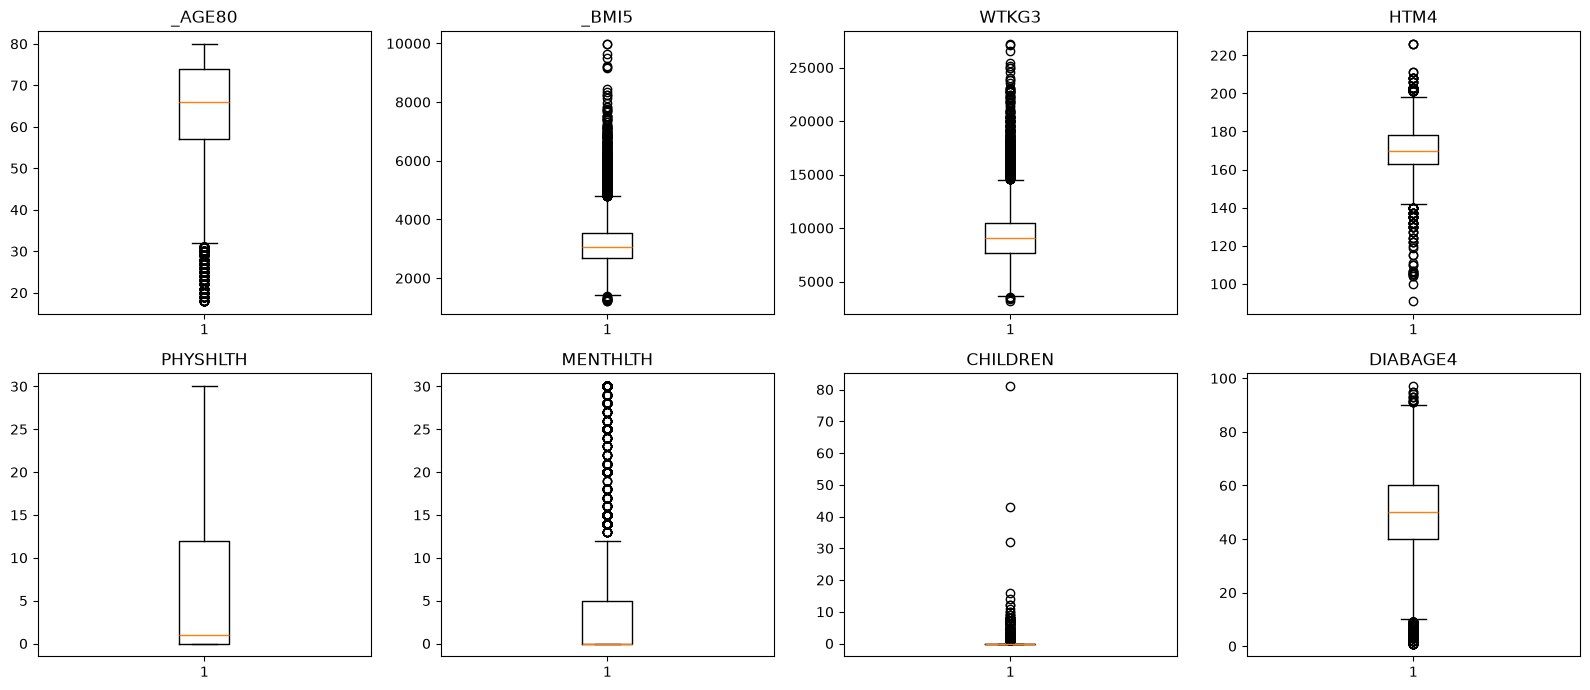

In [22]:
# %% Cek outlier (hanya fitur numerik kontinu)
import matplotlib.pyplot as plt

num_cols = ["_AGE80", "_BMI5", "WTKG3", "HTM4", "PHYSHLTH", "MENTHLTH",
            "SLEPTIM1", "_DRNKWK2", "CHILDREN", "DIABAGE4"]
num_cols = [c for c in num_cols if c in data.columns]

# %% Ringkasan outlier dengan metode IQR
rows = []
for c in num_cols:
    q1, q3 = data[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n_out = ((data[c] < low) | (data[c] > high)).sum()
    rows.append({
        "fitur": c,
        "min": data[c].min(),
        "Q1": q1,
        "median": data[c].median(),
        "Q3": q3,
        "max": data[c].max(),
        "batas_bawah": round(low, 2),
        "batas_atas": round(high, 2),
        "jumlah_outlier": n_out,
        "persen_outlier": round(n_out / len(data) * 100, 2),
    })

outlier_df = pd.DataFrame(rows).sort_values("persen_outlier", ascending=False)
print(outlier_df.to_string(index=False))

# %% Visualisasi boxplot
n = len(num_cols)
ncols = 4
nrows = -(-n // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows))
axes = axes.flatten()

for ax, c in zip(axes, num_cols):
    ax.boxplot(data[c].dropna(), vert=True)
    ax.set_title(c)

for ax in axes[n:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

GENHLTH    -0.205760
_AGE80     -0.187545
DIFFWALK    0.185850
CVDSTRK3    0.183093
EMPLOY1    -0.179667
CHCCOPD3    0.176095
PHYSHLTH   -0.163923
CHCKDNY2    0.157846
HAVARTH4    0.130690
DEAF        0.115562
PNEUVAC4    0.113844
DIFFALON    0.106905
VETERAN3    0.100171
SEXVAR      0.095640
PERSDOC3   -0.095287
INCOME3     0.090267
_SMOKER3    0.089457
BLIND       0.084037
DIFFDRES    0.083743
CHCOCNC1    0.081948
Name: _MICHD, dtype: float64


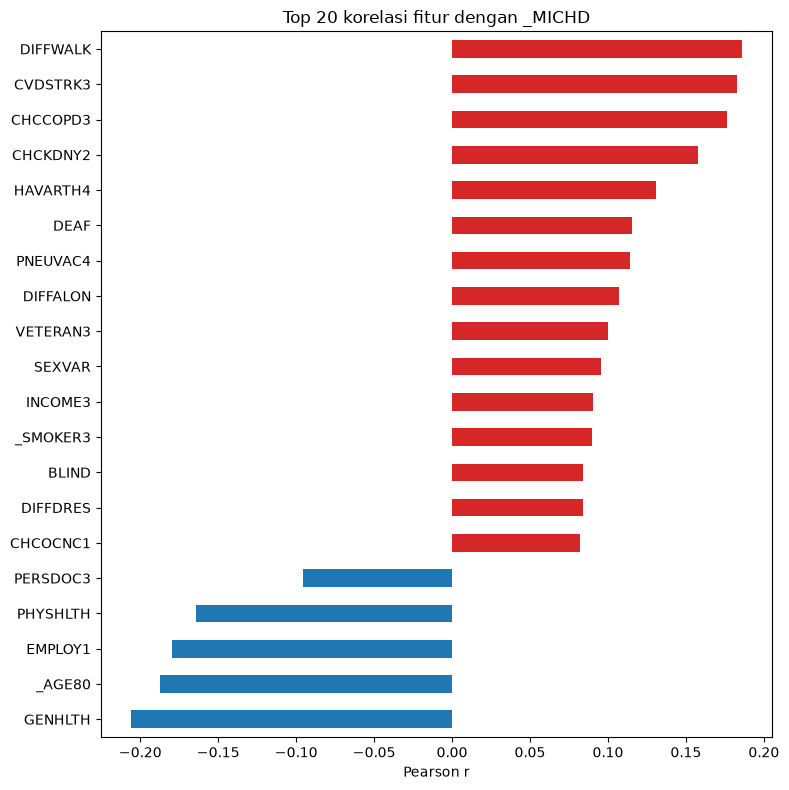

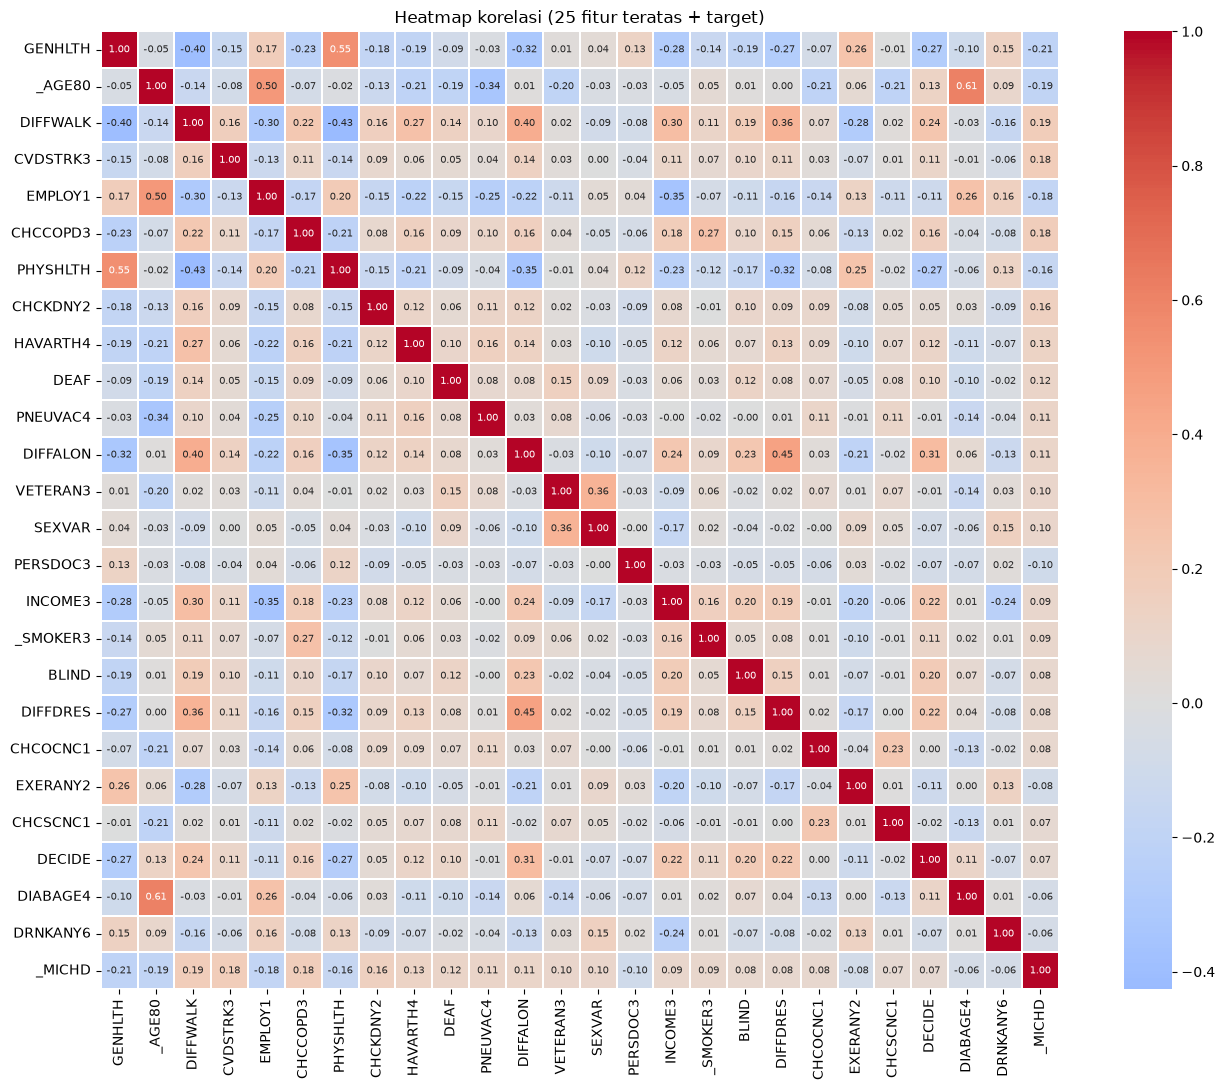

fitur_1 fitur_2        r
  _BMI5   WTKG3 0.848753


In [23]:
# %%
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Pastikan target numerik 0/1
df_corr = data.copy()
df_corr["_MICHD"] = df_corr["_MICHD"].astype(int)

corr = df_corr.corr(method="pearson", numeric_only=True)

# %%
# 1) Korelasi tiap fitur terhadap target (_MICHD)
target_corr = corr["_MICHD"].drop("_MICHD").sort_values(key=abs, ascending=False)
print(target_corr.head(20))

plt.figure(figsize=(8, 8))
top = target_corr.head(20).sort_values()
colors = ["tab:red" if v > 0 else "tab:blue" for v in top]
top.plot(kind="barh", color=colors)
plt.title("Top 20 korelasi fitur dengan _MICHD")
plt.xlabel("Pearson r")
plt.tight_layout(); plt.show()

# %%
# 2) Heatmap korelasi: 25 fitur teratas terhadap target + target
top_cols = target_corr.head(25).index.tolist() + ["_MICHD"]
plt.figure(figsize=(14, 11))
sns.heatmap(df_corr[top_cols].corr(), cmap="coolwarm", center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7},
            square=True, linewidths=0.3)
plt.title("Heatmap korelasi (25 fitur teratas + target)")
plt.tight_layout(); plt.show()

# %%
# 3) Pasangan fitur dengan korelasi antar-fitur tinggi (|r| > 0.8)
feat_corr = corr.drop(index="_MICHD", columns="_MICHD")
upper = feat_corr.where(np.triu(np.ones(feat_corr.shape, dtype=bool), k=1))

high_pairs = (upper.stack()
                   .rename("r")
                   .reset_index()
                   .rename(columns={"level_0": "fitur_1", "level_1": "fitur_2"}))
high_pairs = high_pairs[high_pairs["r"].abs() > 0.8].sort_values("r", key=abs, ascending=False)
print(high_pairs.to_string(index=False))

In [24]:
# Cek value counts untuk semua fitur
for col in data.columns:
    print(f"\n{'=' * 60}")
    print(f"Fitur: {col}")
    print(f"Jumlah nilai unik: {data[col].nunique(dropna=False)}")
    print(f"{'=' * 60}")

    print(data[col].value_counts(dropna=False).to_string())


Fitur: _STATE
Jumlah nilai unik: 49
_STATE
36.0    3355
53.0    1904
18.0    1364
24.0    1296
31.0    1262
17.0    1229
12.0    1225
55.0    1132
26.0    1113
48.0    1048
27.0    1042
39.0    1013
20.0    1009
23.0    1003
45.0     992
21.0     873
19.0     872
49.0     866
54.0     856
4.0      741
13.0     693
51.0     673
8.0      649
40.0     630
1.0      586
29.0     580
33.0     578
34.0     573
5.0      570
15.0     565
6.0      552
46.0     547
25.0     536
38.0     514
30.0     512
41.0     449
22.0     446
50.0     431
44.0     425
10.0     414
56.0     384
2.0      361
35.0     350
37.0     335
28.0     309
16.0     282
42.0     277
32.0     201
11.0     195

Fitur: IYEAR
Jumlah nilai unik: 2
IYEAR
2024    36448
2025     1364

Fitur: SEXVAR
Jumlah nilai unik: 2
SEXVAR
1.0    19965
2.0    17847

Fitur: _AGE80
Jumlah nilai unik: 63
_AGE80
80.0    4046
70.0    1328
65.0    1272
72.0    1260
68.0    1245
67.0    1233
74.0    1202
77.0    1196
73.0    1183
69.0    1177
75.0   

In [25]:
data['CHILDREN'].value_counts()

CHILDREN
0.0     32135
1.0      2911
2.0      1718
3.0       678
4.0       222
5.0        77
6.0        35
7.0        15
8.0         8
9.0         3
10.0        2
12.0        2
43.0        1
32.0        1
14.0        1
81.0        1
11.0        1
16.0        1
Name: count, dtype: int64

In [26]:
# Konversi nilai ke satuan aktual
data["HTM4"] = data["HTM4"] / 100
data["WTKG3"] = data["WTKG3"] / 100
data["_BMI5"] = data["_BMI5"] / 100

In [27]:
data

,_STATE,IYEAR,SEXVAR,_AGE80,MARITAL,_EDUCAG,INCOME3,EMPLOY1,RENTHOM1,VETERAN3,...,DECIDE,DIFFWALK,DIFFDRES,DIFFALON,_SMOKER3,USENOW3,_RFBING6,DRNKANY6,FLUSHOT7,PNEUVAC4
0,1.0,2024,1.0,54.0,1.0,2.0,9.0,1.0,2.0,2.0,...,2.0,2.0,2.0,2.0,4.0,3.0,1.0,2.0,1.0,1.0
3,1.0,2024,2.0,80.0,1.0,4.0,8.0,7.0,1.0,2.0,...,2.0,1.0,2.0,2.0,3.0,3.0,1.0,2.0,1.0,1.0
4,1.0,2024,1.0,63.0,2.0,4.0,10.0,1.0,2.0,2.0,...,2.0,2.0,2.0,2.0,4.0,3.0,1.0,2.0,2.0,2.0
7,1.0,2024,1.0,79.0,1.0,2.0,7.0,7.0,1.0,2.0,...,2.0,2.0,2.0,2.0,4.0,3.0,1.0,2.0,1.0,1.0
8,1.0,2024,2.0,80.0,1.0,2.0,7.0,7.0,1.0,2.0,...,2.0,1.0,2.0,2.0,4.0,3.0,1.0,2.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64429,56.0,2024,1.0,69.0,1.0,4.0,8.0,1.0,1.0,2.0,...,2.0,2.0,2.0,2.0,4.0,3.0,1.0,1.0,1.0,1.0
64430,56.0,2024,1.0,56.0,1.0,4.0,9.0,1.0,1.0,1.0,...,2.0,2.0,2.0,2.0,4.0,3.0,1.0,1.0,1.0,2.0
64434,56.0,2024,1.0,56.0,1.0,4.0,7.0,1.0,1.0,1.0,...,2.0,2.0,2.0,2.0,4.0,3.0,1.0,2.0,1.0,1.0
64437,56.0,2024,2.0,49.0,1.0,2.0,5.0,8.0,1.0,2.0,...,1.0,1.0,2.0,1.0,1.0,3.0,1.0,2.0,2.0,1.0


In [28]:
for col in data.columns:
    print(f"\n{'='*50}")
    print(f"Fitur: {col}")
    print(f"Jumlah nilai unik: {data[col].nunique()}")
    print("="*50)

    print(data[col].value_counts(dropna=False))


Fitur: _STATE
Jumlah nilai unik: 49
_STATE
36.0    3355
53.0    1904
18.0    1364
24.0    1296
31.0    1262
17.0    1229
12.0    1225
55.0    1132
26.0    1113
48.0    1048
27.0    1042
39.0    1013
20.0    1009
23.0    1003
45.0     992
21.0     873
19.0     872
49.0     866
54.0     856
4.0      741
13.0     693
51.0     673
8.0      649
40.0     630
1.0      586
29.0     580
33.0     578
34.0     573
5.0      570
15.0     565
6.0      552
46.0     547
25.0     536
38.0     514
30.0     512
41.0     449
22.0     446
50.0     431
44.0     425
10.0     414
56.0     384
2.0      361
35.0     350
37.0     335
28.0     309
16.0     282
42.0     277
32.0     201
11.0     195
Name: count, dtype: int64

Fitur: IYEAR
Jumlah nilai unik: 2
IYEAR
2024    36448
2025     1364
Name: count, dtype: int64

Fitur: SEXVAR
Jumlah nilai unik: 2
SEXVAR
1.0    19965
2.0    17847
Name: count, dtype: int64

Fitur: _AGE80
Jumlah nilai unik: 63
_AGE80
80.0    4046
70.0    1328
65.0    1272
72.0    1260
68.0   

Jumlah nilai unik: 3
PERSDOC3
1.0    20022
2.0    16663
3.0     1127
Name: count, dtype: int64

Fitur: MEDCOST1
Jumlah nilai unik: 2
MEDCOST1
2.0    34813
1.0     2999
Name: count, dtype: int64

Fitur: CHECKUP1
Jumlah nilai unik: 5
CHECKUP1
1.0    36171
2.0     1030
3.0      329
4.0      235
8.0       47
Name: count, dtype: int64

Fitur: GENHLTH
Jumlah nilai unik: 5
GENHLTH
3.0    15272
4.0    10200
2.0     7035
5.0     4135
1.0     1170
Name: count, dtype: int64

Fitur: PHYSHLTH
Jumlah nilai unik: 31
PHYSHLTH
0.0     17850
30.0     5724
2.0      2276
5.0      1651
3.0      1533
10.0     1486
15.0     1333
1.0      1222
20.0      949
7.0       858
4.0       839
14.0      482
25.0      388
6.0       277
8.0       198
12.0      138
28.0      137
21.0      108
29.0       62
9.0        42
16.0       41
18.0       38
27.0       34
17.0       28
22.0       24
26.0       22
11.0       20
24.0       19
13.0       19
23.0        9
19.0        5
Name: count, dtype: int64

Fitur: MENTHLTH
Jumlah 

In [29]:
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Helper
# ------------------------------------------------------------
def to_binary(df, col, yes, no):
    """Petakan yes -> 1, no -> 0. Semua kode lain (7, 9, dst) jadi NaN."""
    df[col] = df[col].map({yes: 1, no: 0})

def onehot(df, col, invalid=(7, 9), prefix=None):
    """
    1) Kode invalid (Don't know / Refused) -> NaN
    2) One-hot encoding
    3) Baris yang aslinya NaN tetap NaN di semua kolom dummy
       (bukan 0 semua)
    """
    prefix = prefix or col
    s = df[col].replace(list(invalid), np.nan).astype("Int64")
    mask = s.isna()
    dummies = pd.get_dummies(s, prefix=prefix, dtype=float)
    dummies[mask] = np.nan
    return pd.concat([df.drop(columns=col), dummies], axis=1)

# ------------------------------------------------------------
# BINARY (1 = Yes -> 1, 2 = No -> 0)
# ------------------------------------------------------------
# SEXVAR: 1 = Male, 2 = Female  ->  Male = 0, Female = 1
to_binary(data, "SEXVAR", yes=2, no=1)

# VETERAN3: 1 = Yes, 2 = No
to_binary(data, "VETERAN3", yes=1, no=2)

# _URBSTAT: 1 = Urban, 2 = Rural  ->  Urban = 1, Rural = 0
to_binary(data, "_URBSTAT", yes=1, no=2)

# FLUSHOT7, PNEUVAC4: 1 = Yes, 2 = No
for col in ["FLUSHOT7", "PNEUVAC4"]:
    to_binary(data, col, yes=1, no=2)

# _RFBING6: 1 = No, 2 = Yes, 9 = DK/Refused  (KEBALIKAN dari yang lain!)
to_binary(data, "_RFBING6", yes=2, no=1)

# Semua yang kodenya 1 = Yes, 2 = No
binary_features = [
    "MEDCOST1", "EXERANY2", "CVDSTRK3", "CHCSCNC1", "CHCOCNC1",
    "CHCCOPD3", "ADDEPEV3", "CHCKDNY2", "HAVARTH4",
    "DEAF", "BLIND", "DECIDE", "DIFFWALK", "DIFFDRES", "DIFFALON",
]
for col in binary_features:
    to_binary(data, col, yes=1, no=2)

# ------------------------------------------------------------
# ORDINAL
# ------------------------------------------------------------
# GENHLTH: 1 = Excellent ... 5 = Poor; 7, 9 -> NaN
data["GENHLTH"] = data["GENHLTH"].replace([7, 9], np.nan)

# ------------------------------------------------------------
# ONE-HOT (nominal)
# ------------------------------------------------------------
data = onehot(data, "MARITAL")
data = onehot(data, "EMPLOY1",   invalid=(9,))
data = onehot(data, "RENTHOM1",  invalid=(7, 9))
data = onehot(data, "_IMPRACE",  invalid=())          # 1-6, tidak ada kode invalid
data = onehot(data, "PERSDOC3",  invalid=(7, 9))
data = onehot(data, "_ASTHMS1",  invalid=(9,))
data = onehot(data, "_SMOKER3",  invalid=(9,))
data = onehot(data, "USENOW3",   invalid=(7, 9))

# ------------------------------------------------------------
# VERIFIKASI
# ------------------------------------------------------------
all_binary = (
    ["SEXVAR", "VETERAN3", "_URBSTAT", "FLUSHOT7", "PNEUVAC4", "_RFBING6"]
    + binary_features
)
for col in all_binary:
    vals = set(data[col].dropna().unique())
    assert vals <= {0, 1}, f"{col} punya nilai tak terduga: {vals}"
    print(f"{col:10s} ->", data[col].value_counts(dropna=False).to_dict())

SEXVAR     -> {0: 19965, 1: 17847}
VETERAN3   -> {0: 31241, 1: 6571}
_URBSTAT   -> {1: 31810, 0: 6002}
FLUSHOT7   -> {1: 22862, 0: 14950}
PNEUVAC4   -> {1: 24684, 0: 13128}
_RFBING6   -> {0: 35203, 1: 2609}
MEDCOST1   -> {0: 34813, 1: 2999}
EXERANY2   -> {1: 24283, 0: 13529}
CVDSTRK3   -> {0: 34143, 1: 3669}
CHCSCNC1   -> {0: 33558, 1: 4254}
CHCOCNC1   -> {0: 30843, 1: 6969}
CHCCOPD3   -> {0: 32301, 1: 5511}
ADDEPEV3   -> {0: 27945, 1: 9867}
CHCKDNY2   -> {0: 32252, 1: 5560}
HAVARTH4   -> {1: 20519, 0: 17293}
DEAF       -> {0: 32144, 1: 5668}
BLIND      -> {0: 34291, 1: 3521}
DECIDE     -> {0: 32199, 1: 5613}
DIFFWALK   -> {0: 25359, 1: 12453}
DIFFDRES   -> {0: 34869, 1: 2943}
DIFFALON   -> {0: 32872, 1: 4940}


In [30]:
data.info()
data["_MICHD"] = data["_MICHD"].map({1.0: 1, 2.0: 0}).astype(int)

<class 'pandas.DataFrame'>
Index: 37812 entries, 0 to 64438
Data columns (total 74 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   _STATE      37812 non-null  float64
 1   IYEAR       37812 non-null  int64  
 2   SEXVAR      37812 non-null  int64  
 3   _AGE80      37812 non-null  float64
 4   _EDUCAG     37812 non-null  float64
 5   INCOME3     37812 non-null  float64
 6   VETERAN3    37812 non-null  int64  
 7   CHILDREN    37812 non-null  float64
 8   _URBSTAT    37812 non-null  int64  
 9   _BMI5       37812 non-null  float64
 10  DIABETE4    37812 non-null  float64
 11  WTKG3       37812 non-null  float64
 12  HTM4        37812 non-null  float64
 13  MEDCOST1    37812 non-null  int64  
 14  CHECKUP1    37812 non-null  float64
 15  GENHLTH     37812 non-null  float64
 16  PHYSHLTH    37812 non-null  float64
 17  MENTHLTH    37812 non-null  float64
 18  EXERANY2    37812 non-null  int64  
 19  CVDSTRK3    37812 non-null  int64  
 20  

In [31]:
# 1 = minum alkohol dalam 30 hari terakhir, 0 = tidak
data['DRNKANY6'] = data['DRNKANY6'].map({1.0: 1, 2.0: 0})

print(data['DRNKANY6'].value_counts(dropna=False))

DRNKANY6
0    23833
1    13979
Name: count, dtype: int64


In [32]:
data = data[(data['CHILDREN'] < 30) | (data['CHILDREN'].isna())]
data = data.drop(columns=['WTKG3','HTM4'])

In [33]:
data['CHILDREN'].value_counts()

CHILDREN
0.0     32135
1.0      2911
2.0      1718
3.0       678
4.0       222
5.0        77
6.0        35
7.0        15
8.0         8
9.0         3
10.0        2
12.0        2
14.0        1
11.0        1
16.0        1
Name: count, dtype: int64

In [34]:
data.to_csv(r"C:\Users\s2\Documents\RKI\BRFSS\brfss2024_diabetes.csv", index=False)

In [35]:
data['_MICHD'].value_counts()

_MICHD
0    29447
1     8362
Name: count, dtype: int64

In [36]:
data['_MICHD'].value_counts()

_MICHD
0    29447
1     8362
Name: count, dtype: int64

In [37]:
data.info()

<class 'pandas.DataFrame'>
Index: 37809 entries, 0 to 64438
Data columns (total 72 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   _STATE      37809 non-null  float64
 1   IYEAR       37809 non-null  int64  
 2   SEXVAR      37809 non-null  int64  
 3   _AGE80      37809 non-null  float64
 4   _EDUCAG     37809 non-null  float64
 5   INCOME3     37809 non-null  float64
 6   VETERAN3    37809 non-null  int64  
 7   CHILDREN    37809 non-null  float64
 8   _URBSTAT    37809 non-null  int64  
 9   _BMI5       37809 non-null  float64
 10  DIABETE4    37809 non-null  float64
 11  MEDCOST1    37809 non-null  int64  
 12  CHECKUP1    37809 non-null  float64
 13  GENHLTH     37809 non-null  float64
 14  PHYSHLTH    37809 non-null  float64
 15  MENTHLTH    37809 non-null  float64
 16  EXERANY2    37809 non-null  int64  
 17  CVDSTRK3    37809 non-null  int64  
 18  CHCSCNC1    37809 non-null  int64  
 19  CHCOCNC1    37809 non-null  int64  
 20  